# P2.18 — What foreign buyers pay, and where they buy

**Question:** RQ5.2 (how has foreign investment in residential property evolved, and is it associated with higher regional prices?).
`p2_05`, `p2_14` and `p2_06` already look at foreign *residents* and second homes; this notebook is about foreign *buyers*.

INE gives the median sale price per m2 by the buyer's tax residence (national territory, EU, other countries) nationally and for each
municipality, from 4Q2019. It gives no count of sales by buyer, and a cell is blank when there are too few transactions. So:
the **premium** (foreign median over domestic median) is a price gap, not a measure of investment, and a municipality with a
foreign-buyer price is one with enough foreign purchases, which is the only signal of **where** they buy. How much money came in is
not measured: Banco de Portugal's real-estate direct investment was not found in BPstat (`config/sources.yaml`).

In [1]:
import pandas as pd

from pthousing.analysis import foreign_buyers as fb
from pthousing.analysis import supply
from pthousing.config import MUNI_KEY
from pthousing.data import interim
from pthousing.viz import charts, dashboard, style

style.apply_style()
buyer = interim.read("ine_price_by_buyer")
national = interim.read("ine_price_by_buyer_national")
sales = interim.read("ine_median_price_sqm")
panel = dashboard.load_panel()
info = (
    panel.drop_duplicates(MUNI_KEY)
    .set_index(MUNI_KEY)[["coast_class", "density_class", "tourist"]]
    .join(supply.area_of(panel).rename("area"))
)
premium = fb.national_premium(national)
markets = fb.foreign_markets(buyer, sales)
print(
    f"{premium.index.min():%Y-%m} to {premium.index.max():%Y-%m}; yearly snapshots are the 4th quarter"
)

2019-10 to 2026-04; yearly snapshots are the 4th quarter


## Step 1 — The premium
Foreign buyers pay more per m2 than domestic buyers. Nationally the gap is large and falling; inside a municipality it is smaller
(the rest is geography: foreign buyers buy in the dearer places).

buyer,domestic,eu,other_foreign,premium_foreign_pct,premium_eu_pct,premium_other_foreign_pct
period_start,,,,,,
2019-10-01,1071.0,1674.0,2484.0,69.0,56.3,131.9
2020-10-01,1169.0,1707.0,2588.0,65.6,46.0,121.4
2021-10-01,1273.0,1788.0,2565.0,65.4,40.5,101.5
2022-10-01,1454.0,2032.0,2497.0,53.9,39.8,71.7
2023-10-01,1574.0,2032.0,2647.0,48.4,29.1,68.2
2024-10-01,1747.0,2140.0,2789.0,39.2,22.5,59.6
2025-10-01,2051.0,2448.0,3157.0,34.8,19.4,53.9


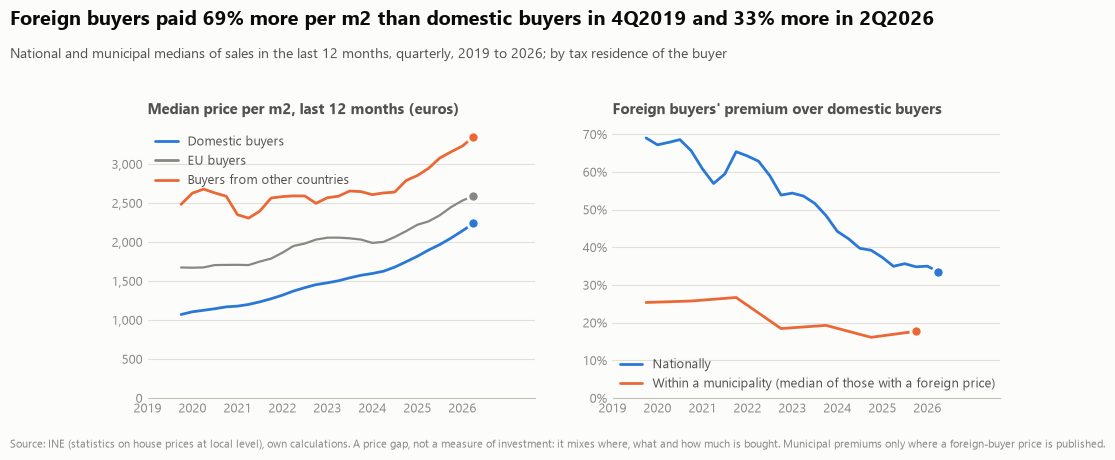

In [2]:
fig = charts.foreign_buyers(premium, markets)
style.save_fig(fig, "p2", "foreign_buyers")
yearly = premium[premium.index.month == 10].round(1)
style.save_table(yearly.reset_index(), "p2", "foreign_buyer_premium")
yearly[
    [
        "domestic",
        "eu",
        "other_foreign",
        "premium_foreign_pct",
        "premium_eu_pct",
        "premium_other_foreign_pct",
    ]
]

## Step 2 — Where foreign buyers are active
Municipalities with a foreign-buyer price each year, the share of all sales in them, and the within-municipality premium.

In [3]:
style.save_table(markets.round(1).reset_index(), "p2", "foreign_markets_by_year")
markets.round(1)

,priced_n,foreign_priced_n,share_of_sales_pct,median_premium_pct,share_paying_more_pct
year,,,,,
2019,286,42,49.6,25.3,95.2
2020,282,37,43.6,25.7,97.3
2021,298,43,46.7,26.7,88.4
2022,301,57,55.8,18.4,93.0
2023,300,67,61.1,19.3,89.6
2024,303,61,55.8,16.1,86.9
2025,305,54,50.3,17.7,87.0


A **foreign market** is a municipality with a foreign-buyer price in at least four of the seven yearly snapshots (2019-2025). By kind of
place, and the median growth of domestic buyers' prices (4Q2019 to 4Q2025, log points) in markets and elsewhere:

In [4]:
cross = fb.cross_section(buyer, sales, info)
groups = pd.concat(
    {
        c: fb.by_group(cross, c).rename_axis("class")
        for c in ("coast_class", "density_class", "tourist")
    },
    names=["typology"],
).round(1)
style.save_table(groups.reset_index(), "p2", "foreign_markets_by_typology")
print(f"{len(cross)} municipalities, {int(cross['foreign_market'].sum())} foreign markets")
groups

278 municipalities, 49 foreign markets


municipalities_n  foreign_markets_n  \
typology      class                                               
coast_class   coast                       80                 40   
              estuary                      9                  1   
              inland                     189                  8   
density_class intermediate                83                 22   
              rural                      160                 13   
              urban                       35                 14   
tourist       other                      221                 20   
              tourist                     34                 25   
              unknown                     23                  4   

                            foreign_market_share_pct  median_growth_markets  \
typology      class                                                           
coast_class   coast                             50.0                   66.6   
              estuary                           11.1                   42.1   
              inland                             4.2                   57.4   
density_class intermediate                      26.5                   66.1   
              rural                              8.1                   60.8   
              urban                             40.0                   71.8   
tourist       other                              9.0                   67.7   
              tourist                           73.5                   64.3   
              unknown                           17.4                   63.1   

                            median_growth_others  
typology      class                               
coast_class   coast                         69.1  
              estuary                       78.9  
              inland                        53.2  
density_class intermediate                  63.5  
              rural                         51.2  
              urban                         74.1  
tourist       other                         57.0  
              tourist                       71.8  
              unknown                       70.5

## Step 3 — Are foreign markets where prices are higher, or rose more?
Outcome: the change in domestic buyers' prices 2019-2025 (so foreign prices do not enter it) and the 2025 level. The flag is added to
district effects, the log of 2019 sales (a foreign price needs enough sales, which also go with big markets) and the coast, density and
tourist classes. Standard errors are clustered by district (20 areas).

In [5]:
growth = fb.association(cross, "growth_log_pts")
level = fb.association(cross, "log_price_end")
style.save_table(growth.round(3).reset_index(), "p2", "foreign_markets_price_growth")
style.save_table(level.round(3).reset_index(), "p2", "foreign_markets_price_level")
display_cols = ["coef", "ci_low", "ci_high", "p_value", "n"]
print("growth (log points):")
print(growth[display_cols].round(2).to_string())
print("level (percent):")
print(level[display_cols].round(2).to_string())

growth (log points):
                           coef  ci_low  ci_high  p_value    n
specification                                                 
no controls                8.55    2.63    14.47     0.00  278
district                   1.18   -3.81     6.18     0.64  278
district, sales           -0.77   -8.99     7.44     0.85  278
district, sales, typology -4.37  -15.96     7.21     0.46  255
level (percent):
                            coef  ci_low  ci_high  p_value    n
specification                                                  
no controls                84.30   63.88   104.73     0.00  278
district                   45.93   32.34    59.53     0.00  278
district, sales             3.62  -11.81    19.05     0.65  278
district, sales, typology  -8.06  -24.15     8.04     0.33  255


### Sensitivity to the definition of a foreign market
One year or more, two, four (used) or all seven.

In [6]:
rows = []
for years in (1, 2, 4, 7):
    c = fb.cross_section(buyer, sales, info, min_years=years)
    for outcome, name in (("growth_log_pts", "growth"), ("log_price_end", "level")):
        a = fb.association(c, outcome)
        for spec in ("district", "district, sales, typology"):
            r = a.loc[spec]
            rows.append(
                {
                    "min_years": years,
                    "markets_n": int(c["foreign_market"].sum()),
                    "outcome": name,
                    "specification": spec,
                    "coef": r["coef"],
                    "ci_low": r["ci_low"],
                    "ci_high": r["ci_high"],
                }
            )
sens = pd.DataFrame(rows).round(2)
style.save_table(sens, "p2", "foreign_markets_sensitivity")
sens

,min_years,markets_n,outcome,specification,coef,ci_low,ci_high
0,1,78,growth,district,-1.23,-5.26,2.79
1,1,78,growth,"district, sales, typology",-6.07,-15.10,2.97
2,1,78,level,district,38.24,28.64,47.85
3,1,78,level,"district, sales, typology",-7.09,-21.02,6.83
4,2,64,growth,district,-1.78,-6.14,2.59
5,2,64,growth,"district, sales, typology",-7.46,-16.25,1.32
6,2,64,level,district,41.41,31.22,51.60
7,2,64,level,"district, sales, typology",-6.76,-19.70,6.18
8,4,49,growth,district,1.18,-3.81,6.18
9,4,49,growth,"district, sales, typology",-4.37,-15.96,7.21


## Key numbers

In [7]:
nat = premium[premium.index.month == 10]
print(
    f"national premium of foreign over domestic buyers: {nat['premium_foreign_pct'].iloc[0]:.0f}% (4Q2019), {nat['premium_foreign_pct'].iloc[-1]:.0f}% (4Q2025), "
    f"{premium['premium_foreign_pct'].iloc[-1]:.0f}% (2Q2026); EU {nat['premium_eu_pct'].iloc[0]:.0f}% to {nat['premium_eu_pct'].iloc[-1]:.0f}%, "
    f"other countries {nat['premium_other_foreign_pct'].iloc[0]:.0f}% to {nat['premium_other_foreign_pct'].iloc[-1]:.0f}%"
)
print(
    f"domestic median {nat['domestic'].iloc[0]:,.0f} to {nat['domestic'].iloc[-1]:,.0f} EUR/m2 (+{100 * (nat['domestic'].iloc[-1] / nat['domestic'].iloc[0] - 1):.0f}%), "
    f"foreign {nat['foreign'].iloc[0]:,.0f} to {nat['foreign'].iloc[-1]:,.0f} (+{100 * (nat['foreign'].iloc[-1] / nat['foreign'].iloc[0] - 1):.0f}%)"
)
print(
    f"within a municipality: median premium {markets['median_premium_pct'].iloc[0]:.0f}% (2019), {markets['median_premium_pct'].iloc[-1]:.0f}% (2025); "
    f"foreign price in {markets['foreign_priced_n'].min()} to {markets['foreign_priced_n'].max()} of ~300 municipalities a year, holding {markets['share_of_sales_pct'].min():.0f}% to {markets['share_of_sales_pct'].max():.0f}% of sales"
)
tou = groups.loc["tourist"]
coast = groups.loc["coast_class"]
print(
    f"foreign markets: {int(cross['foreign_market'].sum())} municipalities; {coast.loc['coast', 'foreign_market_share_pct']:.0f}% of coastal, "
    f"{coast.loc['inland', 'foreign_market_share_pct']:.0f}% of inland; {tou.loc['tourist', 'foreign_market_share_pct']:.0f}% of tourist"
)
for name, a in (("growth", growth), ("level", level)):
    print(
        f"{name}: raw {a.loc['no controls', 'coef']:.1f} [{a.loc['no controls', 'ci_low']:.1f}, {a.loc['no controls', 'ci_high']:.1f}]; "
        f"district {a.loc['district', 'coef']:.1f} [{a.loc['district', 'ci_low']:.1f}, {a.loc['district', 'ci_high']:.1f}]; "
        f"district, sales, typology {a.loc['district, sales, typology', 'coef']:.1f} "
        f"[{a.loc['district, sales, typology', 'ci_low']:.1f}, {a.loc['district, sales, typology', 'ci_high']:.1f}]"
    )

national premium of foreign over domestic buyers: 69% (4Q2019), 35% (4Q2025), 33% (2Q2026); EU 56% to 19%, other countries 132% to 54%
domestic median 1,071 to 2,051 EUR/m2 (+92%), foreign 1,810 to 2,765 (+53%)
within a municipality: median premium 25% (2019), 18% (2025); foreign price in 37 to 67 of ~300 municipalities a year, holding 44% to 61% of sales
foreign markets: 49 municipalities; 50% of coastal, 4% of inland; 74% of tourist
growth: raw 8.6 [2.6, 14.5]; district 1.2 [-3.8, 6.2]; district, sales, typology -4.4 [-16.0, 7.2]
level: raw 84.3 [63.9, 104.7]; district 45.9 [32.3, 59.5]; district, sales, typology -8.1 [-24.2, 8.0]
